# 07 // Feature abundance analysis

This notebook:
- Checks which taxa are more abundant between urbanization levels, taking into account age as well.
- Checks which genera and species are dominant in the samples of each urbanization level. 
- When deciding on the taxa we use several methods to only keep the ones they all identify. 

We use the following:
- **ANCOM-BC** through the QIIME 2 plugin `q2-composition` (`qiime composition ancombc`). It corrects for the sampling fraction of each sample (sequencing depth and composition) and allows covariates, so the model is `urbanization + age` with Urban as reference level.
- **CLR transform + tests** in Python. On the CLR values: a linear model `CLR ~ urbanization + age` (F-test for urbanization), a Kruskal–Wallis test, and a Spearman correlation with the urbanization gradient (Urban = 0 … Rural = 3).

All p-values are corrected for multiple testing with Benjamini–Hochberg (q-values). Significant means q < 0.05.

## Setup

In [1]:
import os
import sys
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from qiime2 import Artifact

# Work from the repository root (this notebook is one level inside it, in notebooks/)
if Path.cwd().name == "notebooks":
    os.chdir("..")
print("Working directory:", Path.cwd())

# This makes qiime available to "!" shell commands
env_bin = str(Path(sys.executable).parent)
os.environ["PATH"] = env_bin + os.pathsep + os.environ["PATH"]

# scratch
scratch = Path("/cluster/scratch") / os.environ.get("USER", "")
if scratch.exists():
    tmp_dir = scratch / "africangut" / "tmp"
    tmp_dir.mkdir(parents=True, exist_ok=True)
    os.environ["TMPDIR"] = str(tmp_dir)

# Inputs and outputs
RESULTS = Path("results")
TAXONOMY_DIR = RESULTS / "04_taxonomy"                  # feature tables from notebook 04
DA_DIR = RESULTS / "07_differential_abundance"          # QIIME 2 files of this notebook
DA_DIR.mkdir(parents=True, exist_ok=True)
METADATA = Path("data/raw/african_gut_microbiomes_metadata.tsv")
if not METADATA.exists():                                
    METADATA = Path("african_gut_microbiomes_metadata.tsv")
QIIME_METADATA = DA_DIR / "07_metadata.tsv"              # written in section 5

# Taxonomic levels of the Bracken tables
LEVELS = {"G": "genus", "S": "species"}

# Urbanization levels:
URBANIZATION_ORDER = ["Urban", "Peri-urban", "Peri-rural", "Hinterland"]
COLOURS = {"Urban": "#2a78d6", "Peri-urban": "#eb6834", "Peri-rural": "#1baf7a", "Hinterland": "#eda100"}
PLOT_LABELS = {"Hinterland": "Rural"}   # in plots, "Hinterland" is labelled "Rural"

# Colours for taxa:
TAXA_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
OTHER_COLOUR = "#c3c2b7"
# Diverging colours for fold changes: 
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL = LinearSegmentedColormap.from_list("sequential", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])

# Settings
MIN_PREVALENCE = 0.10        # present in at least 10% of samples
MIN_MEAN_RELATIVE = 1e-4     # mean relative abundance of at least 0.01%
PSEUDOCOUNT = 0.5            # added to the counts before the transform
ALPHA = 0.05                 # significance level for q-values

# Plot style:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# QIIME 2 plugin used for ANCOM-BC (section 5)
HAS_COMPOSITION = importlib.util.find_spec("q2_composition") is not None
print("q2-composition (ANCOM-BC) installed:", HAS_COMPOSITION)

Working directory: /cluster/home/mozdemir/microbiomes
q2-composition (ANCOM-BC) installed: True


## 1. Samples, urbanization and age

From the read tracking table of notebook 04: Urbanization, country, batch and the flags.
From the metadata: Age (which is checked first). 

In [2]:
tracking = pd.read_csv(RESULTS / "04_read_tracking.tsv", sep="\t", index_col="sample_id")
metadata = pd.read_csv(METADATA, sep="\t", index_col="id")

# Flags from notebooks 01-04 
FLAGS = [f for f in ["low_depth", "low_retention_qc", "high_host", "low_depth_hostfree", "low_classified"]
         if f in tracking.columns]

samples = tracking[["country_iso3", "urbanization", "batch", "read_length"] + FLAGS].copy()
samples["age"] = pd.to_numeric(metadata["age"].reindex(samples.index), errors="coerce")
samples["urbanization"] = pd.Categorical(samples["urbanization"], categories=URBANIZATION_ORDER)
samples["urbanization_rank"] = samples["urbanization"].cat.codes       # Urban = 0 ... Hinterland = 3
samples["flagged"] = samples[FLAGS].astype(bool).any(axis=1)

print("Samples:", len(samples), "| flagged in notebooks 01-04:", samples["flagged"].sum(),
      "| missing age:", samples["age"].isna().sum())
pd.crosstab(samples["urbanization"], samples["country_iso3"], margins=True)

Samples: 53 | flagged in notebooks 01-04: 9 | missing age: 0


country_iso3,CMR,GNB,MDG,TZA,All
urbanization,,,,,
Urban,10,0,0,0,10
Peri-urban,2,0,0,8,10
Peri-rural,0,0,17,0,17
Hinterland,0,16,0,0,16
All,12,16,17,8,53


In [3]:
# Age per urbanization level, and a Kruskal-Wallis test of whether it differs between levels
age_groups = [group.dropna() for _, group in samples.groupby("urbanization", observed=True)["age"]]
age_test = stats.kruskal(*age_groups)
print(f"Kruskal-Wallis test of age between urbanization levels: H = {age_test.statistic:.1f}, p = {age_test.pvalue:.2g}")

samples.groupby("urbanization", observed=True)["age"].describe().round(1)

Kruskal-Wallis test of age between urbanization levels: H = 5.4, p = 0.14


,count,mean,std,min,25%,50%,75%,max
urbanization,,,,,,,,
Urban,10.0,40.5,16.3,22.0,25.8,39.5,53.5,65.0
Peri-urban,10.0,31.7,10.4,19.0,24.5,29.5,37.5,48.0
Peri-rural,17.0,35.8,8.8,26.0,29.0,33.0,42.0,58.0
Hinterland,16.0,30.4,12.9,19.0,20.0,25.5,34.8,60.0


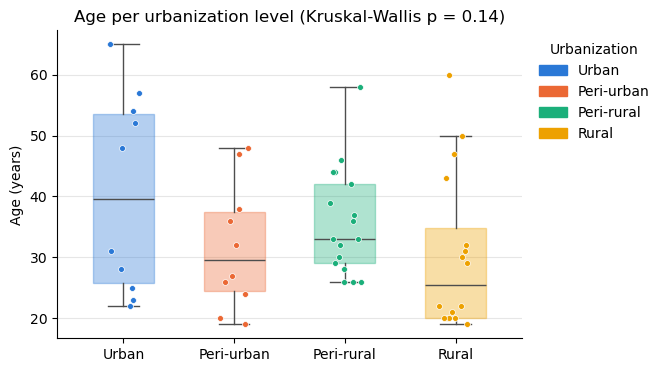

In [4]:
# Box plot of age per urbanization level, with one dot per sample
levels = [level for level in URBANIZATION_ORDER if (samples["urbanization"] == level).any()]
rng = np.random.default_rng(42)          # for the horizontal jitter of the dots

fig, ax = plt.subplots(figsize=(6, 4))
for i, level in enumerate(levels):
    ages = samples.loc[samples["urbanization"] == level, "age"].dropna()
    box = ax.boxplot(ages, positions=[i], widths=0.55, patch_artist=True, showfliers=False)
    box["boxes"][0].set(facecolor=COLOURS[level], alpha=0.35, edgecolor=COLOURS[level])
    for part in ["whiskers", "caps", "medians"]:
        for line in box[part]:
            line.set(color="0.3", linewidth=1)
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(ages)), ages, s=18, color=COLOURS[level],
               edgecolor="white", linewidth=0.5, zorder=3)
ax.set_xticks(range(len(levels)))
ax.set_xticklabels([PLOT_LABELS.get(level, level) for level in levels])
ax.set_xlim(-0.6, len(levels) - 0.4)
ax.set_ylabel("Age (years)")
ax.set_title(f"Age per urbanization level (Kruskal-Wallis p = {age_test.pvalue:.2g})")
ax.grid(axis="y", color="0.9")
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=COLOURS[level], label=PLOT_LABELS.get(level, level)) for level in levels],
          title="Urbanization", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

fig.savefig(RESULTS / "07_age_per_urbanization.png", dpi=150, bbox_inches="tight")
plt.show()

P-value is 0.14. This suggests that age does not differ significantly between the urbanization levels, but the medians follow the urbanization gradient: Urban ≈ 40, Peri-rural ≈ 33, Peri-urban ≈ 29 and Rural ≈ 25 years, and most Rural participants are young adults (20–32). With 10–17 samples per level the test has little power, so a non-significant p-value does not mean the levels have the same ages. We will therefore keep age as a covariate in ANCOM-BC and in the CLR linear model. Because each level is mostly one country, these age differences also partly reflect how each study recruited its participants.

## 2. Loading the feature tables

The Bracken tables have one column per taxon (NCBI taxonomy ID) and one row per sample. We name every taxon after its genus or species from the taxonomy, keep only Bacteria and Archaea, and finally round the Bracken estimates to whole read pairs.

In [5]:
RANK_NAMES = {"d": "domain", "k": "kingdom", "p": "phylum", "c": "class", "o": "order",
              "f": "family", "g": "genus", "s": "species"}
RANK_ORDER = ["domain", "kingdom", "phylum", "class", "order", "family", "genus", "species"]


def parse_lineage(taxon):
    # "d__Bacteria;p__Bacteroidota;...;g__Segatella" -> {"domain": "Bacteria", ..., "genus": "Segatella"}
    lineage = {}
    for part in str(taxon).split(";"):
        part = part.strip()
        if len(part) > 3 and part[1:3] == "__":
            lineage[RANK_NAMES.get(part[0], part[0])] = part[3:]
    return lineage


def load_level(level):
    # Feature table (rows: samples, columns: taxa) with readable taxon names, Bacteria and Archaea only
    table = Artifact.load(TAXONOMY_DIR / f"bracken_table_{level}.qza").view(pd.DataFrame)
    taxonomy = Artifact.load(TAXONOMY_DIR / f"bracken_taxonomy_{level}.qza").view(pd.DataFrame)
    table.columns = table.columns.astype(str)
    taxonomy.index = taxonomy.index.astype(str)

    # Lineage of every feature: one column per rank
    taxa = taxonomy["Taxon"].to_dict()
    lineage = pd.DataFrame([parse_lineage(taxa.get(f, f)) for f in table.columns], index=table.columns)
    lineage = lineage.reindex(columns=RANK_ORDER)

    # Keeping Bacteria and Archaea
    keep = lineage.isin(["Bacteria", "Archaea"]).any(axis=1)
    if not keep.any():
        print("Warning: no domain found in the taxonomy; keeping all features")
        keep[:] = True
    pct_kept = 100 * table.loc[:, keep].to_numpy().sum() / table.to_numpy().sum()

    # Name of each feature at this level (or the deepest rank that has a name)
    rank = LEVELS[level]
    names = lineage[rank].fillna(lineage.ffill(axis=1).iloc[:, -1]).fillna(pd.Series(table.columns, index=table.columns))

    # Summing features with the same name 
    counts = table.loc[:, keep].T.groupby(names[keep]).sum().T
    counts = counts.round().astype(int).reindex(samples.index)
    lineage = lineage[keep].groupby(names[keep]).first()

    missing = counts.isna().any(axis=1).sum()
    print(f"{rank:>8}: {counts.shape[1]} taxa, {pct_kept:.2f}% of Bracken read pairs are Bacteria/Archaea"
          + (f", {missing} samples missing!" if missing else ""))
    return counts, lineage


counts, lineages = {}, {}
for level in LEVELS:
    counts[level], lineages[level] = load_level(level)

# Relative abundance (fraction of the read pairs of each sample)
rel = {level: table.div(table.sum(axis=1), axis=0) for level, table in counts.items()}

   genus: 1208 taxa, 97.52% of Bracken read pairs are Bacteria/Archaea
 species: 3328 taxa, 97.51% of Bracken read pairs are Bacteria/Archaea


## 3. Overview

Most abundant phyla and genera per urbanization level:

In [6]:
# Mean relative abundance (%) of the main phyla per urbanization level
phylum = rel["G"].T.groupby(lineages["G"]["phylum"].reindex(rel["G"].columns).fillna("Unassigned")).sum().T
phylum_means = 100 * phylum.groupby(samples["urbanization"], observed=True).mean().T
phylum_means = phylum_means.loc[phylum_means.mean(axis=1).sort_values(ascending=False).index]
phylum_means.columns = [PLOT_LABELS.get(level, level) for level in phylum_means.columns]
phylum_means.head(8).round(1)

,Urban,Peri-urban,Peri-rural,Rural
phylum,,,,
Bacteroidota,65.5,51.9,34.7,5.6
Bacillota,28.8,37.0,38.1,51.4
Pseudomonadota,2.9,5.8,21.8,20.2
Actinomycetota,2.0,4.6,3.6,17.2
Methanobacteriota,0.1,0.1,0.4,2.8
Thermodesulfobacteriota,0.2,0.2,0.3,2.5
Spirochaetota,0.1,0.0,0.8,0.1
Verrucomicrobiota,0.4,0.2,0.3,0.0


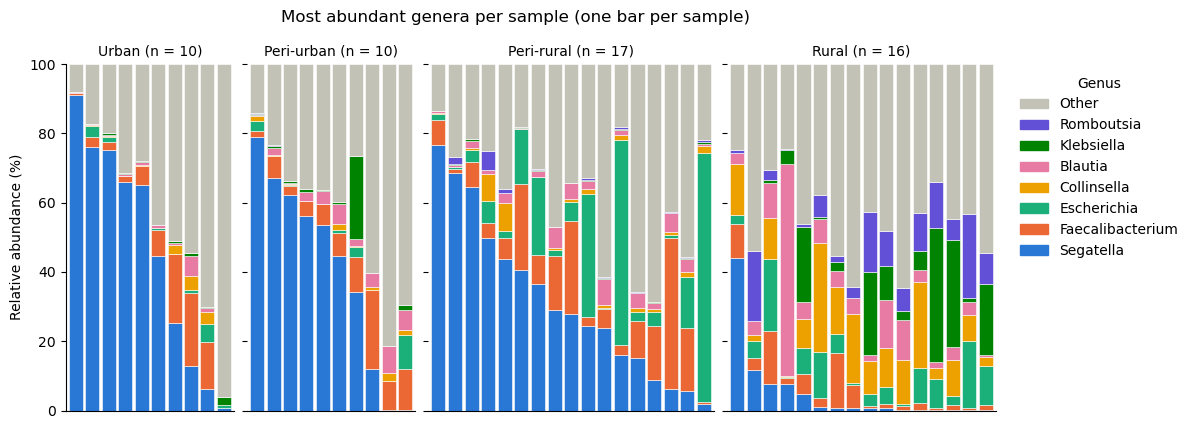

In [7]:
def plot_top_taxa(rel_table, n_top, legend_title, file):
    top = rel_table.mean().sort_values(ascending=False).index[:n_top]
    plot_data = 100 * rel_table[top]
    plot_data["Other"] = 100 - plot_data.sum(axis=1)
    colours = TAXA_COLOURS[:n_top] + [OTHER_COLOUR]

    levels = [level for level in URBANIZATION_ORDER if (samples["urbanization"] == level).any()]
    sizes = [(samples["urbanization"] == level).sum() for level in levels]
    fig, axes = plt.subplots(1, len(levels), figsize=(12, 4.5), sharey=True,
                             gridspec_kw={"width_ratios": sizes, "wspace": 0.06})
    for ax, level in zip(np.atleast_1d(axes), levels):
        level_data = plot_data.loc[samples.index[samples["urbanization"] == level]].sort_values(top[0], ascending=False)
        x = np.arange(len(level_data))
        bottom = np.zeros(len(level_data))
        for taxon, colour in zip(level_data.columns, colours):
            ax.bar(x, level_data[taxon], bottom=bottom, color=colour, width=0.85, edgecolor="white", linewidth=0.4)
            bottom += level_data[taxon].to_numpy()
        ax.set_title(f"{PLOT_LABELS.get(level, level)} (n = {len(level_data)})", fontsize=10)
        ax.set_xticks([])
        ax.set_xlim(-0.6, len(level_data) - 0.4)
        ax.spines["left"].set_visible(ax is np.atleast_1d(axes)[0])
    np.atleast_1d(axes)[0].set_ylim(0, 100)
    np.atleast_1d(axes)[0].set_ylabel("Relative abundance (%)")
    handles = [Patch(color=colour, label=taxon) for taxon, colour in zip(plot_data.columns, colours)]
    fig.legend(handles=handles[::-1], title=legend_title, frameon=False, loc="upper left", bbox_to_anchor=(0.91, 0.88))
    fig.suptitle("Most abundant genera per sample (one bar per sample)", y=1.0)
    fig.savefig(RESULTS / file, dpi=150, bbox_inches="tight")
    plt.show()
    return top


top_genera = plot_top_taxa(rel["G"], n_top=7, legend_title="Genus", file="07_top_genera_per_sample.png")

In [8]:
# The 15 most abundant genera: mean relative abundance (%) per urbanization level
top15 = rel["G"].mean().sort_values(ascending=False).index[:15]
genus_means = 100 * rel["G"][top15].groupby(samples["urbanization"], observed=True).mean().T
genus_means.columns = [PLOT_LABELS.get(level, level) for level in genus_means.columns]
genus_means.round(2)

,Urban,Peri-urban,Peri-rural,Rural
genus,,,,
Segatella,46.23,40.85,31.71,4.99
Faecalibacterium,7.54,8.13,11.86,4.41
Escherichia,1.23,1.68,14.54,7.28
Collinsella,1.08,0.90,1.71,11.50
Blautia,1.06,3.44,2.76,8.68
Klebsiella,0.56,2.82,0.25,10.20
Romboutsia,0.01,0.05,0.69,8.36
Bacteroides,8.29,4.03,1.05,0.30
Agathobacter,2.46,5.28,3.01,0.20


## 4. Filtering features and files for QIIME 2

QIIME 2 gets the filtered tables, with simple feature IDs and a metadata file with urbanization, age, country and batch.

NOTE: Rare taxa are left out of the tests i.e. present in fewer than 10% of samples or with a mean relative abundance below 0.01%. They still count in the totals used for the relative abundances above.

In [9]:
def filter_features(table):
    prevalence = (table > 0).mean()
    mean_rel = table.div(table.sum(axis=1), axis=0).mean()
    return table.loc[:, (prevalence >= MIN_PREVALENCE) & (mean_rel >= MIN_MEAN_RELATIVE)]


def qiime_ids(names):
    # Taxon name -> feature ID 
    ids = {}
    for name in names:
        new_id = "".join(c if c.isalnum() else "_" for c in name).strip("_") or "unnamed"
        while new_id in ids.values():                    # keeps the IDs unique
            new_id += "_x"
        ids[name] = new_id
    return ids


filtered, ID_OF, NAME_OF = {}, {}, {}
for level, rank in LEVELS.items():
    filtered[level] = filter_features(counts[level])
    ID_OF[level] = qiime_ids(filtered[level].columns)
    NAME_OF[level] = {i: name for name, i in ID_OF[level].items()}
    pct_reads = 100 * filtered[level].to_numpy().sum() / counts[level].to_numpy().sum()
    print(f"{rank:>8}: {filtered[level].shape[1]} of {counts[level].shape[1]} taxa kept for testing "
          f"({pct_reads:.1f}% of the read pairs)")

    # Count table for ANCOM-BC
    table = filtered[level].rename(columns=ID_OF[level])
    Artifact.import_data("FeatureTable[Frequency]", table).save(str(DA_DIR / f"table_{level}_filtered.qza"))

# QIIME 2 metadata file 
qiime_metadata = samples[["urbanization", "age", "country_iso3", "batch"]].copy()
qiime_metadata["urbanization"] = qiime_metadata["urbanization"].astype(str)
with open(QIIME_METADATA, "w") as f:
    f.write("sample-id\turbanization\tage\tcountry_iso3\tbatch\n")
    f.write("#q2:types\tcategorical\tnumeric\tcategorical\tcategorical\n")
    qiime_metadata.to_csv(f, sep="\t", header=False)
print("Metadata for QIIME 2:", QIIME_METADATA)

   genus: 115 of 1208 taxa kept for testing (99.5% of the read pairs)
 species: 260 of 3328 taxa kept for testing (98.0% of the read pairs)
Metadata for QIIME 2: results/07_differential_abundance/07_metadata.tsv


## 5. ANCOM-BC

Model: `urbanization + age`, reference level Urban.
For every taxon and every other level (Peri-urban, Peri-rural, Rural) ANCOM-BC estimates the log fold change compared with Urban, corrected for age and for each sample's sampling fraction, and tests it (q-values with Benjamini–Hochberg).



In [10]:
for level, rank in LEVELS.items():
    table_file = DA_DIR / f"table_{level}_filtered.qza"
    ancombc_file = DA_DIR / f"ancombc_{level}.qza"
    barplot_file = DA_DIR / f"ancombc_{level}_barplot.qzv"
    tabulate_file = DA_DIR / f"ancombc_{level}_table.qzv"
    export_dir = DA_DIR / f"ancombc_{level}"
    if ancombc_file.exists():
        print(f"ANCOM-BC ({rank}) has run already")
        continue
    print(f"Running ANCOM-BC ({rank}) ...")
    !qiime composition ancombc --i-table {table_file} --m-metadata-file {QIIME_METADATA} --p-formula "urbanization + age" --p-reference-levels urbanization::Urban --p-p-adj-method BH --o-differentials {ancombc_file}
    !qiime composition da-barplot --i-data {ancombc_file} --p-significance-threshold {ALPHA} --o-visualization {barplot_file}
    !qiime composition tabulate --i-data {ancombc_file} --o-visualization {tabulate_file}
    !qiime tools export --input-path {ancombc_file} --output-path {export_dir}

Running ANCOM-BC (genus) ...
Saved FeatureData[DifferentialAbundance] to: results/07_differential_abundance/ancombc_G.qza
Usage: qiime composition da-barplot [OPTIONS]

  Displays ANCOMBC/ANCOMBC2 Log-Fold Change values in a barplot and allows
  filtering based on p-value and standard error. If a taxonomy is provided,
  features can be filtered by taxonomy using an interactive tree.

Inputs:
  --i-data ARTIFACT FeatureData[DifferentialAbundance | ANCOMBC2Output]
                         The ANCOMBC or ANCOMBC2 output to visualize.
                                                                    [required]
  --i-taxonomy ARTIFACT FeatureData[Taxonomy]
                         The taxonomy associated with the features present in
                         the data.                                  [optional]
Outputs:
  --o-visualization VISUALIZATION
                                                                    [required]
Miscellaneous:
  --output-dir PATH      Output unspecified 

In [11]:
def load_ancombc(level):
    # ANCOM-BC results as a table
    export_dir = DA_DIR / f"ancombc_{level}"
    if not (export_dir / "lfc_slice.csv").exists():
        return None, None
    parts = {}
    for name in ["lfc", "se", "W", "p_val", "q_val"]:
        part = pd.read_csv(export_dir / f"{name.lower()}_slice.csv", index_col=0)
        part.index = [NAME_OF[level].get(i, i) for i in part.index.astype(str)]
        parts[name] = part
    results = []
    for column in parts["lfc"].columns:
        if column.startswith("urbanization"):
            contrast = pd.DataFrame({name: part[column] for name, part in parts.items()})
            contrast["contrast"] = column.replace("urbanization", "", 1)
            results.append(contrast)
    age = pd.DataFrame({name: part["age"] for name, part in parts.items() if "age" in part.columns})
    return pd.concat(results), age


ancombc, ancombc_age = {}, {}
for level, rank in LEVELS.items():
    ancombc[level], ancombc_age[level] = load_ancombc(level)
    if ancombc[level] is None:
        print(f"{rank:>8}: no ANCOM-BC results")
        continue
    significant = ancombc[level][ancombc[level]["q_val"] < ALPHA]
    print(f"{rank:>8}: significant taxa (q < {ALPHA}) per contrast vs Urban:",
          significant["contrast"].value_counts().reindex(URBANIZATION_ORDER[1:], fill_value=0).to_dict(),
          f"| associated with age: {(ancombc_age[level]['q_val'] < ALPHA).sum() if len(ancombc_age[level]) else 'n/a'}")

# Strongest genus results: largest fold changes among the significant ones
if ancombc["G"] is not None:
    display(ancombc["G"][ancombc["G"]["q_val"] < ALPHA]
            .assign(abs_lfc=lambda d: d["lfc"].abs()).sort_values("abs_lfc", ascending=False)
            .drop(columns="abs_lfc").head(20).round(3))

   genus: significant taxa (q < 0.05) per contrast vs Urban: {'Peri-urban': 5, 'Peri-rural': 33, 'Hinterland': 72} | associated with age: 0
 species: significant taxa (q < 0.05) per contrast vs Urban: {'Peri-urban': 5, 'Peri-rural': 58, 'Hinterland': 157} | associated with age: 0


,lfc,se,W,p_val,q_val,contrast
Paraclostridium,6.231,0.612,10.186,0.000,0.000,Hinterland
Romboutsia,6.184,0.351,17.600,0.000,0.000,Hinterland
Odoribacter,-5.972,0.615,-9.716,0.000,0.000,Hinterland
Cutibacterium,5.605,0.447,12.526,0.000,0.000,Peri-rural
Sarcina,5.473,0.899,6.088,0.000,0.000,Hinterland
Phocaeicola,-5.451,0.774,-7.045,0.000,0.000,Hinterland
Terrisporobacter,5.321,0.572,9.308,0.000,0.000,Hinterland
Bacteroides,-5.156,0.701,-7.356,0.000,0.000,Hinterland
Succinivibrio,5.013,1.518,3.303,0.001,0.005,Peri-rural
Arachnia,4.977,0.442,11.266,0.000,0.000,Hinterland


## 7. CLR-based tests

CLR transform: turns each sample's counts into log-ratios against the sample's geometric mean, which removes the dependence on sequencing depth and makes the values suitable for standard tests.
Per taxon:
- **Linear model** `CLR ~ urbanization + age`, F-test for urbanization. The coefficients give the CLR difference of each level from Urban, adjusted for age. Possible to later compare these to ANCOM-BC's fold changes.
- **Kruskal–Wallis** test between the four levels, no age correction here.
- **Spearman correlation** with the urbanization gradient (Urban = 0 … Rural = 3): a positive ρ meaning the taxon becomes more abundant towards rural.

NOTE: A taxon that is absent from a sample will be at or around the pseudocount. The linear model is sensitive to such values, but the Kruskal–Wallis much less, so we consider more than one.

In [12]:
def clr(table, pseudocount=PSEUDOCOUNT):
    logged = np.log(table + pseudocount)
    return logged.sub(logged.mean(axis=1), axis=0)


def bh_adjust(pvalues):
    # Benjamini-Hochberg q-values 
    p = pd.Series(pvalues, dtype=float)
    ordered = p.dropna().sort_values()
    n = len(ordered)
    q = ordered.to_numpy() * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    return pd.Series(np.clip(q, 0, 1), index=ordered.index).reindex(p.index)


def residual_ss(X, Y):
    # Residual sum of squares of a least-squares fit, for every column of Y at once
    beta, *_ = np.linalg.lstsq(X, Y, rcond=None)
    return ((Y - X @ beta) ** 2).sum(axis=0), beta


def clr_tests(table, sample_info):
    # All CLR-based tests for every taxon of a (filtered) count table
    values = clr(table)
    info = sample_info.loc[values.index]
    results = pd.DataFrame(index=values.columns)
    results["prevalence"] = (table > 0).mean()
    results["mean_rel_abundance_pct"] = 100 * table.div(table.sum(axis=1), axis=0).mean()

    # Linear model CLR ~ urbanization + age (samples with an age only), F-test for urbanization
    has_age = info["age"].notna().to_numpy()
    Y = values.to_numpy()[has_age]
    levels = [level for level in URBANIZATION_ORDER[1:] if (info["urbanization"][has_age] == level).any()]
    dummies = np.column_stack([(info["urbanization"][has_age] == level).to_numpy(float) for level in levels])
    X_reduced = np.column_stack([np.ones(has_age.sum()), info["age"][has_age].to_numpy(float)])
    X_full = np.column_stack([X_reduced, dummies])
    rss_reduced, _ = residual_ss(X_reduced, Y)
    rss_full, beta = residual_ss(X_full, Y)
    df1, df2 = len(levels), has_age.sum() - X_full.shape[1]
    F = ((rss_reduced - rss_full) / df1) / (rss_full / df2)
    results["lm_F"] = F
    results["lm_p"] = stats.f.sf(F, df1, df2)
    for i, level in enumerate(levels):
        results[f"lm_coef_{level}"] = beta[2 + i]          # CLR difference from Urban, adjusted for age

    # Kruskal-Wallis between levels and Spearman correlation with the urbanization gradient
    groups = [values[info["urbanization"] == level] for level in URBANIZATION_ORDER if (info["urbanization"] == level).any()]
    kw_p, rho, rho_p = [], [], []
    for taxon in values.columns:
        try:
            kw_p.append(stats.kruskal(*[g[taxon] for g in groups]).pvalue)
        except ValueError:                                  # all values identical
            kw_p.append(np.nan)
        r = stats.spearmanr(info["urbanization_rank"], values[taxon])
        rho.append(r[0])
        rho_p.append(r[1])
    results["kw_p"] = kw_p
    results["spearman_rho"] = rho
    results["spearman_p"] = rho_p

    for test in ["lm", "kw", "spearman"]:
        results[f"{test}_q"] = bh_adjust(results[f"{test}_p"])
    return results


clr_results = {}
for level, rank in LEVELS.items():
    clr_results[level] = clr_tests(filtered[level], samples)
    n_sig = {test: int((clr_results[level][f"{test}_q"] < ALPHA).sum()) for test in ["lm", "kw", "spearman"]}
    print(f"{rank:>8}: significant taxa (q < {ALPHA}): linear model {n_sig['lm']}, "
          f"Kruskal-Wallis {n_sig['kw']}, Spearman {n_sig['spearman']} (of {len(clr_results[level])})")

   genus: significant taxa (q < 0.05): linear model 83, Kruskal-Wallis 89, Spearman 78 (of 115)
 species: significant taxa (q < 0.05): linear model 175, Kruskal-Wallis 184, Spearman 166 (of 260)


## 8. Consensus between methods

A taxon counts as differentially abundant (**consensus**) when ANCOM-BC finds it (q < 0.05 in at least one contrast vs Urban) and at least one of the CLR tests confirms it (linear model or Kruskal–Wallis, q < 0.05). 

In [13]:
def combine_results(level_):
    results = clr_results[level_].copy()
    results["lm_sig"] = results["lm_q"] < ALPHA
    results["kw_sig"] = results["kw_q"] < ALPHA
    if ancombc[level_] is not None:
        contrasts = [level for level in URBANIZATION_ORDER[1:] if level in set(ancombc[level_]["contrast"])]
        lfc = ancombc[level_].pivot(columns="contrast", values="lfc")[contrasts].add_prefix("ancombc_lfc_")
        q_val = ancombc[level_].pivot(columns="contrast", values="q_val")[contrasts].add_prefix("ancombc_q_")
        results = results.join(lfc).join(q_val)
        results["ancombc_sig"] = (results.filter(like="ancombc_q_") < ALPHA).any(axis=1)
        results["consensus"] = results["ancombc_sig"] & (results["lm_sig"] | results["kw_sig"])
        # Do ANCOM-BC and the linear model agree on the sign of the Rural vs Urban difference?
        if "ancombc_lfc_Hinterland" in results and "lm_coef_Hinterland" in results:
            results["rural_sign_agrees"] = np.sign(results["ancombc_lfc_Hinterland"]) == np.sign(results["lm_coef_Hinterland"])
    else:
        results["consensus"] = results["lm_sig"] & results["kw_sig"]
    results["direction"] = np.where(results["spearman_q"] < ALPHA,
                                    np.where(results["spearman_rho"] > 0, "higher towards rural", "higher towards urban"),
                                    "no clear gradient")
    results.insert(0, "phylum", lineages[level_]["phylum"].reindex(results.index))
    results.insert(1, "family", lineages[level_]["family"].reindex(results.index))
    return results.sort_values(["consensus", "lm_q"], ascending=[False, True])


combined = {level: combine_results(level) for level in LEVELS}
for level, rank in LEVELS.items():
    c = combined[level]
    print(f"{rank:>8}: {c['consensus'].sum()} consensus taxa:", c.loc[c["consensus"], "direction"].value_counts().to_dict())

show_columns = ["phylum", "family", "mean_rel_abundance_pct", "direction", "spearman_rho", "lm_q", "kw_q"] + \
               [c for c in combined["G"].columns if c.startswith("ancombc_lfc_") or c.startswith("ancombc_q_")]
combined["G"].loc[combined["G"]["consensus"], show_columns].head(30).round(3)

   genus: 73 consensus taxa: {'higher towards urban': 36, 'higher towards rural': 32, 'no clear gradient': 5}
 species: 149 consensus taxa: {'higher towards urban': 89, 'higher towards rural': 52, 'no clear gradient': 8}


,phylum,family,mean_rel_abundance_pct,direction,spearman_rho,lm_q,kw_q,ancombc_lfc_Peri-urban,ancombc_lfc_Peri-rural,ancombc_lfc_Hinterland,ancombc_q_Peri-urban,ancombc_q_Peri-rural,ancombc_q_Hinterland
genus,,,,,,,,,,,,,
Cutibacterium,Actinomycetota,Propionibacteriaceae,0.012,higher towards rural,0.453,0.0,0.0,-1.482,5.605,1.962,0.112,0.000,0.000
Romboutsia,Bacillota,Peptostreptococcaceae,2.774,higher towards rural,0.828,0.0,0.0,0.763,3.462,6.184,0.707,0.000,0.000
Odoribacter,Bacteroidota,Odoribacteraceae,0.150,higher towards urban,-0.799,0.0,0.0,-0.568,-1.468,-5.972,0.784,0.037,0.000
Paraclostridium,Bacillota,Peptostreptococcaceae,0.084,higher towards rural,0.830,0.0,0.0,0.549,3.630,6.231,0.829,0.000,0.000
Actinomyces,Actinomycetota,Actinomycetaceae,0.181,higher towards rural,0.676,0.0,0.0,0.465,0.700,3.661,0.707,0.267,0.000
Intestinibacter,Bacillota,Peptostreptococcaceae,0.808,higher towards rural,0.735,0.0,0.0,1.104,2.034,4.626,0.260,0.001,0.000
Phocaeicola,Bacteroidota,Bacteroidaceae,1.860,higher towards urban,-0.842,0.0,0.0,-0.423,-1.915,-5.451,0.911,0.028,0.000
Bacteroides,Bacteroidota,Bacteroidaceae,2.760,higher towards urban,-0.818,0.0,0.0,-1.341,-2.121,-5.156,0.348,0.002,0.000
Terrisporobacter,Bacillota,Peptostreptococcaceae,0.159,higher towards rural,0.744,0.0,0.0,1.017,2.216,5.321,0.659,0.001,0.000


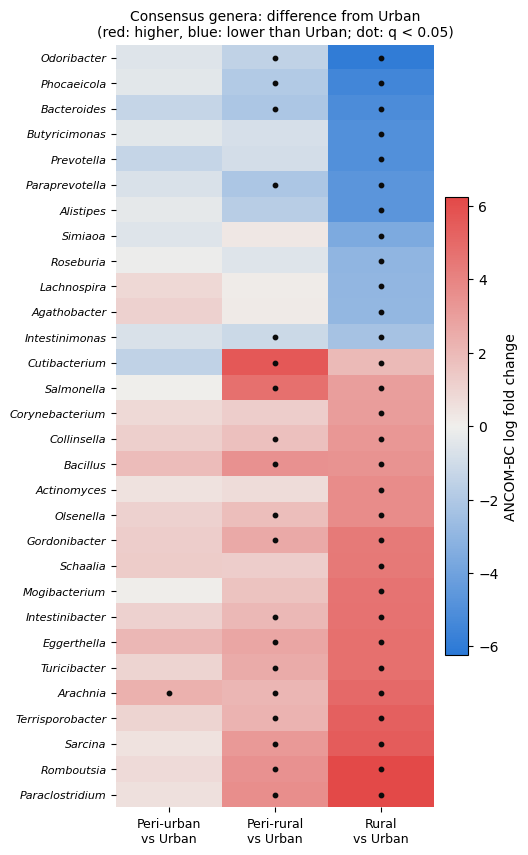

In [15]:
# Heatmap of the consensus genera: difference from Urban per level
c = combined["G"]
consensus_genera = c.index[c["consensus"]][:30]
use_ancombc = ancombc["G"] is not None
prefix = "ancombc_lfc_" if use_ancombc else "lm_coef_"
contrast_levels = [level for level in URBANIZATION_ORDER[1:] if f"{prefix}{level}" in c.columns]

if len(consensus_genera) == 0:
    print("No consensus genera to plot.")
else:
    values = c.loc[consensus_genera, [f"{prefix}{level}" for level in contrast_levels]]
    values = values.sort_values(values.columns[-1])        # sorted by the Rural vs Urban difference
    limit = np.nanmax(np.abs(values.to_numpy()))

    fig, ax = plt.subplots(figsize=(5, 0.28 * len(values) + 1.5))
    image = ax.imshow(values.to_numpy(), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    if use_ancombc:
        for j, level in enumerate(contrast_levels):
            sig = (c.loc[values.index, f"ancombc_q_{level}"] < ALPHA).to_numpy()
            ax.scatter(np.full(sig.sum(), j), np.where(sig)[0], s=10, color="#0b0b0b")
    ax.set_xticks(range(len(contrast_levels)))
    ax.set_xticklabels([f"{PLOT_LABELS.get(level, level)}\nvs Urban" for level in contrast_levels], fontsize=9)
    ax.set_yticks(range(len(values)))
    ax.set_yticklabels(values.index, fontsize=8, style="italic")
    ax.spines[:].set_visible(False)
    bar = fig.colorbar(image, ax=ax, shrink=0.6, pad=0.03)
    bar.set_label("ANCOM-BC log fold change" if use_ancombc else "CLR difference (linear model)")
    ax.set_title("Consensus genera: difference from Urban\n(red: higher, blue: lower than Urban; dot: q < 0.05)", fontsize=10)
    fig.savefig(RESULTS / "07_consensus_heatmap_G.png", dpi=150, bbox_inches="tight")
    plt.show()

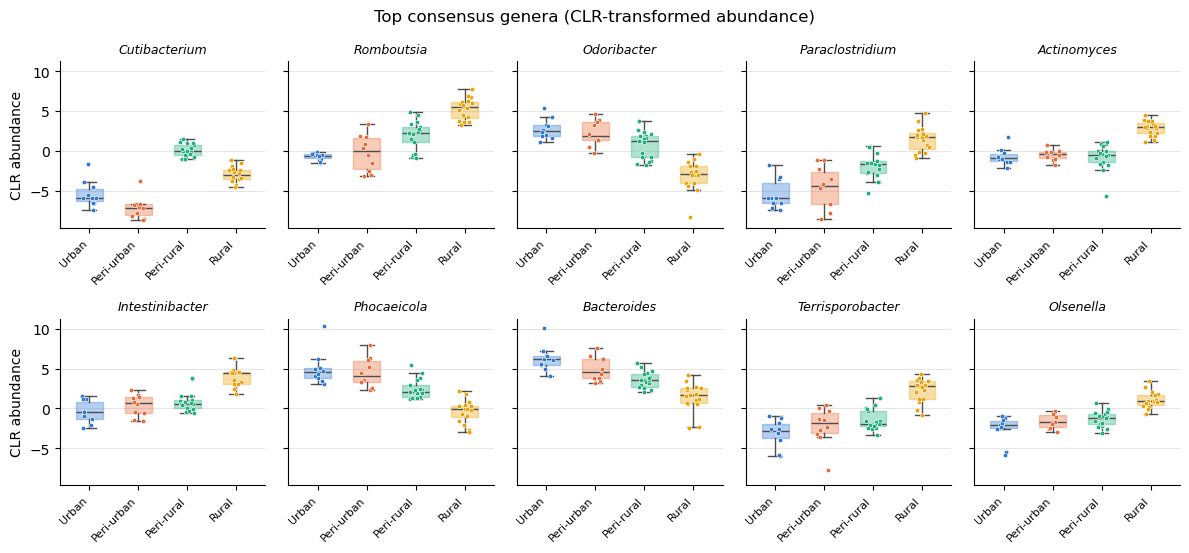

In [18]:
def plot_by_level(table, taxa, ylabel, title, file, n_cols=5):
    # One panel per taxon: box plot of the values per urbanization level, with one dot per sample
    levels = [level for level in URBANIZATION_ORDER if (samples["urbanization"] == level).any()]
    n_rows = int(np.ceil(len(taxa) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.4 * n_cols, 2.8 * n_rows), sharey=True, squeeze=False)
    rng = np.random.default_rng(42)          # for the horizontal jitter of the dots
    for ax, taxon in zip(axes.flat, taxa):
        for i, level in enumerate(levels):
            values = table.loc[samples.index[samples["urbanization"] == level], taxon]
            box = ax.boxplot(values, positions=[i], widths=0.55, patch_artist=True, showfliers=False)
            box["boxes"][0].set(facecolor=COLOURS[level], alpha=0.35, edgecolor=COLOURS[level])
            for part in ["whiskers", "caps", "medians"]:
                for line in box[part]:
                    line.set(color="0.3", linewidth=1)
            ax.scatter(i + rng.uniform(-0.15, 0.15, len(values)), values, s=10, color=COLOURS[level],
                       edgecolor="white", linewidth=0.4, zorder=3)
        ax.set_title(taxon, fontsize=9, style="italic")
        ax.set_xticks(range(len(levels)))
        ax.set_xticklabels([PLOT_LABELS.get(level, level) for level in levels], rotation=45, ha="right", fontsize=8)
        ax.set_xlim(-0.6, len(levels) - 0.4)
        ax.grid(axis="y", color="0.9")
        ax.set_axisbelow(True)
    for ax in axes.flat[len(taxa):]:          # empty panels in the last row
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS / file, dpi=150, bbox_inches="tight")
    plt.show()


# CLR values of the 10 most significant consensus genera (linear model) per urbanization level
top_consensus = list(combined["G"].index[combined["G"]["consensus"]][:10])
if top_consensus:
    plot_by_level(clr(filtered["G"]), top_consensus, ylabel="CLR abundance",
                  title="Top consensus genera (CLR-transformed abundance)", file="07_consensus_genera_clr.png")

In [19]:
# Species level: the consensus species with the strongest evidence
combined["S"].loc[combined["S"]["consensus"],
                  [col for col in show_columns if col in combined["S"].columns]].head(30).round(3)

,phylum,family,mean_rel_abundance_pct,direction,spearman_rho,lm_q,kw_q,ancombc_lfc_Peri-urban,ancombc_lfc_Peri-rural,ancombc_lfc_Hinterland,ancombc_q_Peri-urban,ancombc_q_Peri-rural,ancombc_q_Hinterland
species,,,,,,,,,,,,,
Cutibacterium acnes,Actinomycetota,Propionibacteriaceae,0.012,higher towards rural,0.469,0.0,0.0,-1.601,5.796,1.555,0.059,0.000,0.004
Romboutsia sp. CE17,Bacillota,Peptostreptococcaceae,0.076,higher towards rural,0.872,0.0,0.0,1.717,4.918,7.179,0.272,0.000,0.000
Romboutsia hominis,Bacillota,Peptostreptococcaceae,0.018,higher towards rural,0.865,0.0,0.0,1.069,4.009,5.638,0.453,0.000,0.000
Odoribacter splanchnicus,Bacteroidota,Odoribacteraceae,0.152,higher towards urban,-0.788,0.0,0.0,-0.957,-1.613,-6.481,0.436,0.012,0.000
Paraclostridium bifermentans,Bacillota,Peptostreptococcaceae,0.027,higher towards rural,0.747,0.0,0.0,-0.002,2.454,6.264,0.999,0.002,0.000
Terrisporobacter mayombei,Bacillota,Peptostreptococcaceae,0.015,higher towards rural,0.732,0.0,0.0,-0.129,1.834,5.446,0.966,0.012,0.000
Intestinibacter bartlettii,Bacillota,Peptostreptococcaceae,0.826,higher towards rural,0.781,0.0,0.0,0.714,1.880,4.107,0.498,0.001,0.000
Romboutsia ilealis,Bacillota,Peptostreptococcaceae,2.419,higher towards rural,0.846,0.0,0.0,0.096,3.290,5.694,0.998,0.000,0.000
Schaalia odontolytica,Actinomycetota,Actinomycetaceae,0.254,higher towards rural,0.692,0.0,0.0,0.885,0.848,3.722,0.562,0.402,0.000


## 9. Saving the results

In [20]:
for level, rank in LEVELS.items():
    combined[level].to_csv(RESULTS / f"07_da_results_{level}.tsv", sep="\t", index_label=rank)
    print("Saved", RESULTS / f"07_da_results_{level}.tsv", combined[level].shape)

Saved results/07_da_results_G.tsv (115, 27)
Saved results/07_da_results_S.tsv (260, 27)
